# Exp 8: Song / Ferns task distance vs WTE (sparse vs distance)

**Question:** Are tasks in a sparse-reward GridNavi distribution closer as MDPs than under distance reward — and does that track WTE failing to separate sparse tasks?

**Metric (Song et al., AAMAS 2016):** Ferns bisimulation across two homogeneous MDPs (same S, A, P; different R_g, R_g'), then lift to D(M_g, M_g'). Bisimulation-style with matched actions — not lax/homomorphism.

Fixed-point mirrors google-research `rl_metrics_aaai2021/bisimulation.py`. Deterministic transitions => W1 collapses to d(s', t').


In [2]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np

CODE_DIR = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
for p in (CODE_DIR, CODE_DIR / "scripts", CODE_DIR / "hyper"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from environments.navigation.gridworld import GridNavi, goal_positions
from detect import Detect

NUM_CELLS = 5
MAX_STEPS = 15
GAMMA = 0.99
TOL = 1e-6
SEED = 42
ACTION_DIM = 5  # noop, up, right, down, left
TASK_DISTS = (1, 2, 3, 4)


## Grid model (matches GridNavi transitions / rewards)

Reward is a function of the **next** state after the action (same as `GridNavi.step`).


In [3]:
def state_to_idx(x, y, n=NUM_CELLS):
    return int(x) * n + int(y)


def idx_to_state(i, n=NUM_CELLS):
    return i // n, i % n


def next_state(x, y, action, n=NUM_CELLS):
    """Mirror GridNavi.state_transition for the open square grid."""
    x, y = int(x), int(y)
    if action == 1:  # up
        y = min(y + 1, n - 1)
    elif action == 2:  # right
        x = min(x + 1, n - 1)
    elif action == 3:  # down
        y = max(y - 1, 0)
    elif action == 4:  # left
        x = max(x - 1, 0)
    # action 0 = noop
    return x, y


def reward_at(x, y, goal, distance_reward, n=NUM_CELLS):
    gx, gy = goal
    if x == gx and y == gy:
        return 1.0
    if distance_reward:
        return (-abs(x - gx) - abs(y - gy)) / n
    return -0.1


def build_mdp(goal, distance_reward, n=NUM_CELLS):
    """Returns next_idx[s,a] and rewards[s,a] for Ferns/Song."""
    n_states = n * n
    next_idx = np.zeros((n_states, ACTION_DIM), dtype=np.int32)
    rewards = np.zeros((n_states, ACTION_DIM), dtype=np.float64)
    for s in range(n_states):
        x, y = idx_to_state(s, n)
        for a in range(ACTION_DIM):
            nx, ny = next_state(x, y, a, n)
            next_idx[s, a] = state_to_idx(nx, ny, n)
            rewards[s, a] = reward_at(nx, ny, goal, distance_reward, n)
    return next_idx, rewards


## Song / Ferns cross-MDP distance

Same loop as google-research `Bisimulation._compute`, but rewards come from two MDPs (Song). Deterministic: replace `ot.emd2` with `d[s', t']`.


In [4]:
def song_bisimulation(next_idx, rewards1, rewards2, gamma=GAMMA, tol=TOL):
    """Ferns/Song state metric d' (google-research Bisimulation loop, vectorized).

    d'[s,t] = max_a |R1(s,a)-R2(t,a)| + gamma * d'[s',t']
    Deterministic: W1(d)(P_s^a, P_t^a) = d[s', t'].
    """
    n_states, n_actions = next_idx.shape
    d = np.zeros((n_states, n_states), dtype=np.float64)
    while True:
        best = np.zeros_like(d)
        for a in range(n_actions):
            rdiff = np.abs(rewards1[:, a][:, None] - rewards2[:, a][None, :])
            sp = next_idx[:, a]
            tp = next_idx[:, a]
            # d_next[s, t] = d[sp[s], tp[t]]
            val = rdiff + gamma * d[sp][:, tp]
            np.maximum(best, val, out=best)
        if np.max(np.abs(best - d)) <= tol:
            return best
        d = best


def hausdorff_lift(d):
    """Song Hausdorff lift of a state-state distance matrix."""
    return float(max(d.min(axis=1).max(), d.min(axis=0).max()))


def mean_diag(d):
    return float(np.mean(np.diag(d)))


def pairwise_task_distances(goals, distance_reward, n=NUM_CELLS, gamma=GAMMA):
    """D[i,j] from Song d' between goal i and goal j (Hausdorff + mean-diag)."""
    g = len(goals)
    mdps = [build_mdp(goal, distance_reward, n) for goal in goals]
    D_haus = np.zeros((g, g))
    D_diag = np.zeros((g, g))
    for i in range(g):
        next_idx, r_i = mdps[i]
        for j in range(i, g):
            _, r_j = mdps[j]
            d = song_bisimulation(next_idx, r_i, r_j, gamma=gamma)
            h, m = hausdorff_lift(d), mean_diag(d)
            D_haus[i, j] = D_haus[j, i] = h
            D_diag[i, j] = D_diag[j, i] = m
    return D_haus, D_diag


## Compute D_sparse vs D_distance (task_dist 1–4)


In [5]:
def mean_offdiag(D):
    g = D.shape[0]
    mask = ~np.eye(g, dtype=bool)
    return float(D[mask].mean()) if g > 1 else 0.0


results = {}
for dist_id in TASK_DISTS:
    goals = goal_positions(dist_id, NUM_CELLS)
    Ds_h, Ds_m = pairwise_task_distances(goals, distance_reward=False)
    Dd_h, Dd_m = pairwise_task_distances(goals, distance_reward=True)
    results[dist_id] = {
        "goals": goals,
        "sparse_haus": Ds_h,
        "sparse_diag": Ds_m,
        "dist_haus": Dd_h,
        "dist_diag": Dd_m,
    }
    print(
        f"TD{dist_id} goals={goals}\n"
        f"  mean off-diag Hausdorff  sparse={mean_offdiag(Ds_h):.4f}  distance={mean_offdiag(Dd_h):.4f}\n"
        f"  mean off-diag mean-diag  sparse={mean_offdiag(Ds_m):.4f}  distance={mean_offdiag(Dd_m):.4f}"
    )


TD1 goals=[(4, 4), (4, 3), (3, 4), (3, 3)]
  mean off-diag Hausdorff  sparse=109.9999  distance=126.6333
  mean off-diag mean-diag  sparse=107.8466  distance=124.6719
TD2 goals=[(2, 2), (4, 2), (2, 4), (4, 4)]
  mean off-diag Hausdorff  sparse=109.9999  distance=153.1666
  mean off-diag mean-diag  sparse=108.4430  distance=151.8434
TD3 goals=[(0, 0), (0, 4), (4, 0), (4, 4)]
  mean off-diag Hausdorff  sparse=109.9999  distance=204.8910
  mean off-diag mean-diag  sparse=108.0959  distance=204.5639
TD4 goals=[(0, 0), (0, 1), (1, 0), (1, 1)]
  mean off-diag Hausdorff  sparse=109.9999  distance=126.6333
  mean off-diag mean-diag  sparse=107.8466  distance=124.6719


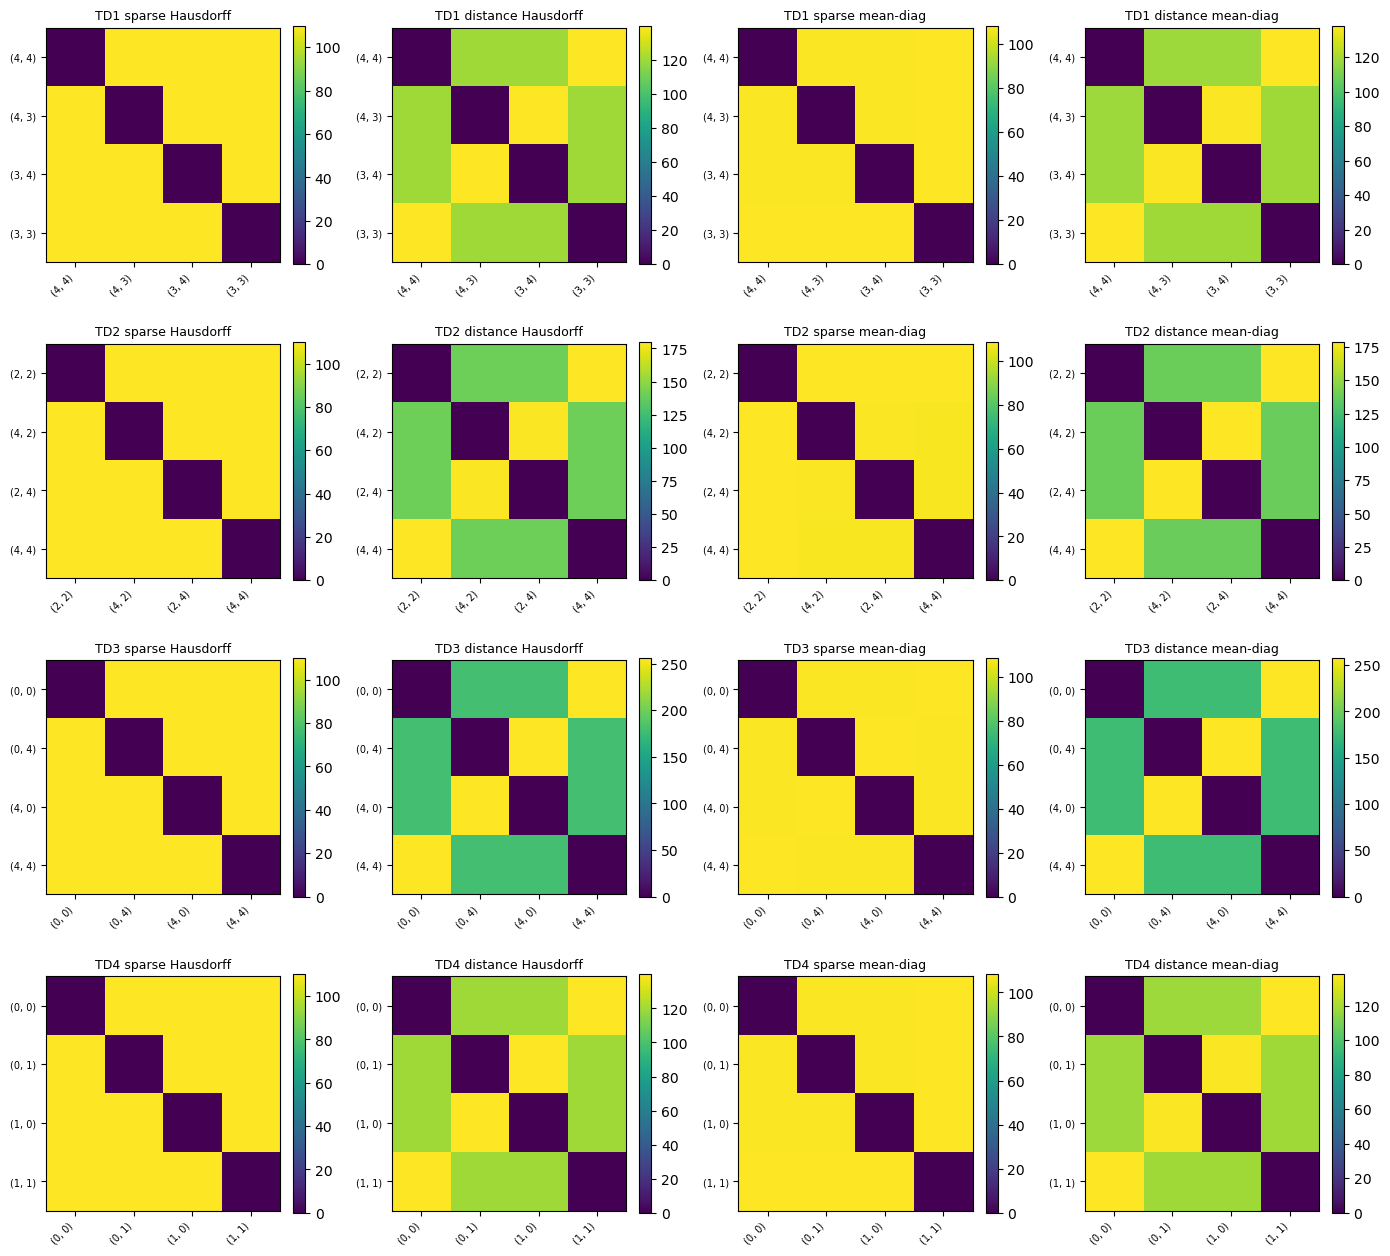

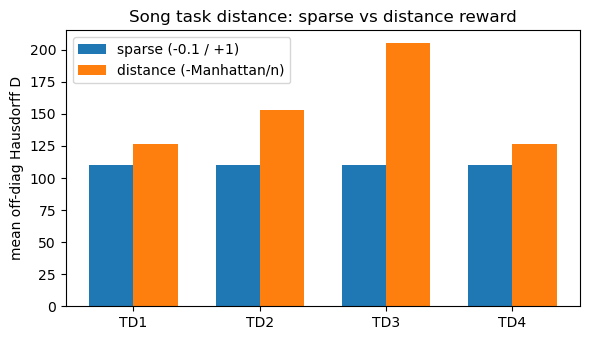

In [6]:
fig, axes = plt.subplots(len(TASK_DISTS), 4, figsize=(14, 3.2 * len(TASK_DISTS)))
if len(TASK_DISTS) == 1:
    axes = np.expand_dims(axes, 0)

col_keys = [
    ("sparse_haus", "sparse Hausdorff"),
    ("dist_haus", "distance Hausdorff"),
    ("sparse_diag", "sparse mean-diag"),
    ("dist_diag", "distance mean-diag"),
]
for row, dist_id in enumerate(TASK_DISTS):
    labels = [f"{g}" for g in results[dist_id]["goals"]]
    for col, (key, title) in enumerate(col_keys):
        ax = axes[row, col]
        D = results[dist_id][key]
        im = ax.imshow(D, cmap="viridis")
        ax.set_xticks(range(len(labels)))
        ax.set_yticks(range(len(labels)))
        ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=7)
        ax.set_yticklabels(labels, fontsize=7)
        ax.set_title(f"TD{dist_id} {title}", fontsize=9)
        fig.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

x = np.arange(len(TASK_DISTS))
w = 0.35
sparse_means = [mean_offdiag(results[d]["sparse_haus"]) for d in TASK_DISTS]
dist_means = [mean_offdiag(results[d]["dist_haus"]) for d in TASK_DISTS]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(x - w / 2, sparse_means, w, label="sparse (-0.1 / +1)")
ax.bar(x + w / 2, dist_means, w, label="distance (-Manhattan/n)")
ax.set_xticks(x)
ax.set_xticklabels([f"TD{d}" for d in TASK_DISTS])
ax.set_ylabel("mean off-diag Hausdorff D")
ax.set_title("Song task distance: sparse vs distance reward")
ax.legend()
plt.tight_layout()
plt.show()


## WTE pairwise distances (same goals / reward modes)

Collect random rollouts (exp7-style), embed with `Detect.lwe`, compare cosine-distance matrices to Song D.


In [ ]:
def collect_goal_sar(goals, distance_reward, num_cells=NUM_CELLS, max_steps=MAX_STEPS, seed=SEED):
    """One SAR array per goal: visit every start cell, random actions."""
    rng = np.random.default_rng(seed)
    n = num_cells * num_cells * max_steps
    out = {}
    for task in goals:
        rows = []
        for j in range(num_cells):
            for k in range(num_cells):
                env = GridNavi(
                    num_cells=num_cells,
                    num_steps=max_steps,
                    distance_reward=distance_reward,
                    starting_state=(j, k),
                    possible_goals=goals,
                )
                env.reset_task(task=task)
                obs, _ = env.reset()
                for _ in range(max_steps):
                    action = int(rng.integers(env.action_space.n))
                    next_obs, reward, terminated, truncated, _ = env.step(action)
                    rows.append([obs[0], obs[1], action, reward, next_obs[0], next_obs[1]])
                    obs = next_obs
                    if terminated or truncated:
                        obs, _ = env.reset()
        out[tuple(task)] = np.asarray(rows[:n], dtype=np.float64)
    return out


def wte_pairwise_matrix(sar_by_goal, detect, action_dim=ACTION_DIM):
    goals = list(sar_by_goal.keys())
    E = np.stack([np.asarray(detect.lwe(sar_by_goal[g], action_dim)).ravel() for g in goals])
    E = E / np.clip(np.linalg.norm(E, axis=1, keepdims=True), 1e-12, None)
    sims = E @ E.T
    return goals, 1.0 - sims


N = NUM_CELLS * NUM_CELLS * MAX_STEPS
OBS_DIM = 2
REFERENCE_NUM = 200
detect = Detect(
    reference_num=REFERENCE_NUM,
    input_dim=OBS_DIM,
    action_dim=ACTION_DIM,
    num_samples=N,
    sars_flag=True,
)
detect.set_reference(OBS_DIM, REFERENCE_NUM, ACTION_DIM)

wte = {}
for dist_id in TASK_DISTS:
    goals = results[dist_id]["goals"]
    sar_sp = collect_goal_sar(goals, distance_reward=False, seed=SEED + dist_id)
    sar_dd = collect_goal_sar(goals, distance_reward=True, seed=SEED + 100 + dist_id)
    _, W_sp = wte_pairwise_matrix(sar_sp, detect)
    _, W_dd = wte_pairwise_matrix(sar_dd, detect)
    wte[dist_id] = {"sparse": W_sp, "distance": W_dd}
    print(
        f"TD{dist_id} WTE mean off-diag  sparse={mean_offdiag(W_sp):.4f}  distance={mean_offdiag(W_dd):.4f}"
    )


In [ ]:
fig, axes = plt.subplots(len(TASK_DISTS), 4, figsize=(14, 3.2 * len(TASK_DISTS)))
if len(TASK_DISTS) == 1:
    axes = np.expand_dims(axes, 0)

for row, dist_id in enumerate(TASK_DISTS):
    panels = [
        (results[dist_id]["sparse_haus"], "Song sparse"),
        (wte[dist_id]["sparse"], "WTE sparse"),
        (results[dist_id]["dist_haus"], "Song distance"),
        (wte[dist_id]["distance"], "WTE distance"),
    ]
    labels = [f"{g}" for g in results[dist_id]["goals"]]
    for col, (D, title) in enumerate(panels):
        ax = axes[row, col]
        im = ax.imshow(D, cmap="viridis")
        ax.set_xticks(range(len(labels)))
        ax.set_yticks(range(len(labels)))
        ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=7)
        ax.set_yticklabels(labels, fontsize=7)
        ax.set_title(f"TD{dist_id} {title}", fontsize=9)
        fig.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

print("Summary (mean off-diagonal):")
print(f"{'TD':>4}  {'Song_sp':>10}  {'Song_dist':>10}  {'WTE_sp':>10}  {'WTE_dist':>10}  {'Song_ratio':>10}")
for dist_id in TASK_DISTS:
    ss = mean_offdiag(results[dist_id]["sparse_haus"])
    sd = mean_offdiag(results[dist_id]["dist_haus"])
    ws = mean_offdiag(wte[dist_id]["sparse"])
    wd = mean_offdiag(wte[dist_id]["distance"])
    ratio = ss / sd if sd > 1e-12 else float("nan")
    print(f"{dist_id:>4}  {ss:10.4f}  {sd:10.4f}  {ws:10.4f}  {wd:10.4f}  {ratio:10.4f}")

print(
    "\nInference: if Song_sp < Song_dist and WTE_sp is flatter than WTE_dist,"
    " sparse tasks are closer as MDPs and harder for trajectory WTE to separate."
)


## Plot MDPs / task distributions used in exp8

Goal sets for TD1–4 on the 5×5 grid, plus example sparse vs distance reward heatmaps for one goal per TD.


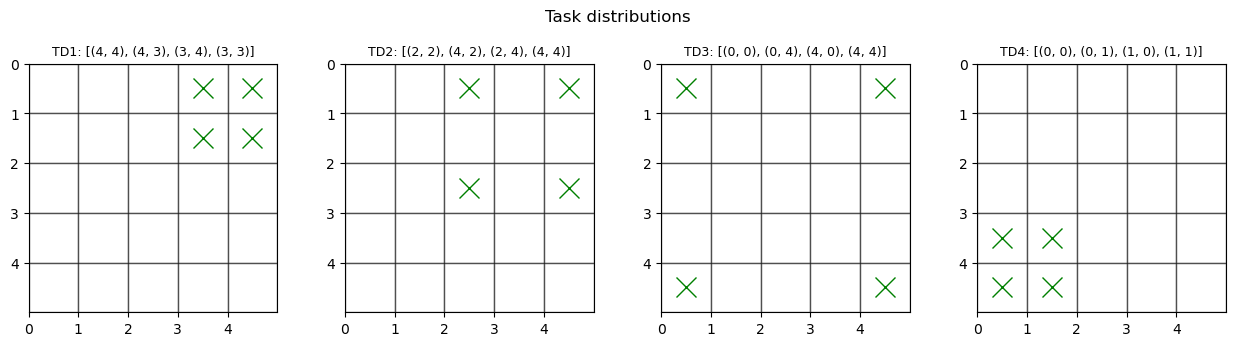

In [8]:
fig, axes = plt.subplots(1, len(TASK_DISTS), figsize=(3.2 * len(TASK_DISTS), 3.2))
axes = np.atleast_1d(axes).ravel()

for ax, dist_id in zip(axes, TASK_DISTS):
    goals = goal_positions(dist_id, NUM_CELLS)
    for x in range(NUM_CELLS):
        for y in range(NUM_CELLS):
            ax.add_patch(Rectangle((x, y), 1, 1, facecolor="w", edgecolor="k", alpha=0.5))
    for gx, gy in goals:
        ax.plot(gx + 0.5, NUM_CELLS - gy - 0.5, "gx", markersize=14, zorder=5)
    ax.set_xlim(0, NUM_CELLS)
    ax.set_ylim(NUM_CELLS, 0)
    ax.set_aspect("equal")
    ax.set_xticks(range(NUM_CELLS))
    ax.set_yticks(range(NUM_CELLS))
    ax.set_title(f"TD{dist_id}: {goals}", fontsize=9)

fig.suptitle("Task distributions", y=1.02)
plt.tight_layout()
plt.show()


In [ ]:
def reward_grid(goal, distance_reward, n=NUM_CELLS):
    """R at each cell (as in GridNavi: reward of being in that cell)."""
    G = np.zeros((n, n))
    for x in range(n):
        for y in range(n):
            # plot with y up in grid coords; imshow row 0 at top => flip y
            G[n - 1 - y, x] = reward_at(x, y, goal, distance_reward, n)
    return G

fig, axes = plt.subplots(len(TASK_DISTS), 2, figsize=(7, 3.0 * len(TASK_DISTS)))
if len(TASK_DISTS) == 1:
    axes = np.expand_dims(axes, 0)

for row, dist_id in enumerate(TASK_DISTS):
    goals = goal_positions(dist_id, NUM_CELLS)
    goal = goals[0]  # one example MDP per TD
    for col, (dr, name) in enumerate([(False, "sparse"), (True, "distance")]):
        ax = axes[row, col]
        G = reward_grid(goal, dr)
        im = ax.imshow(G, cmap="coolwarm")
        gx, gy = goal
        ax.plot(gx, NUM_CELLS - 1 - gy, "kx", markersize=12, markeredgewidth=2)
        ax.set_xticks(range(NUM_CELLS))
        ax.set_yticks(range(NUM_CELLS))
        ax.set_title(f"TD{dist_id} {name} R, goal={goal}", fontsize=9)
        fig.colorbar(im, ax=ax, fraction=0.046)

fig.suptitle("Example MDP reward maps (same P; R differs by goal / reward type)", y=1.01)
plt.tight_layout()
plt.show()
